# 10b · `hate`: Gemini vs HerBERT, Polbert, RoBERTa-BAN-PL na gold standardzie

Który sposób oznaczania hejtu lepiej zgadza się z gold standardem? Porównujemy **na tych samych 600 komentarzach**:

- **klasyfikatory** z notebooka 08 (`reports/gold_model_eval/gold_predictions.csv`) – po dwa warianty: **słownik + model**
  i **sam model** (p ≥ 0,5),
- **Gemini** (`gemini-3.5-flash-lite`, model klasyfikacji wszystkich wydarzeń) z notebooka 09b (`reports/gold_gemini_eval/gold_llm_labels.csv`) – **Gemini + słownik** i **sam Gemini**,
- sam słownik obelg (punkt odniesienia).

**Testy różnic (te same komentarze = próby zależne):** McNemar (dokładny), różnica F1 z bootstrapu par (95% CI), korekta Holma.

Sekcja 5: wykresy gold standardu (zgodność anotatorów, metryki, ROC, macierze pomyłek) – do raportu i prezentacji.


In [1]:
# ── KONFIGURACJA ──────────────────────────────────────────────────────────────
MODEL_PRED = "reports/gold_model_eval/gold_predictions.csv"    # notebook 08
LLM_LABELS = "reports/gold_gemini_eval/gold_llm_labels.csv"       # notebook 09b
OUT_DIR = "reports/gold_gemini_eval"
METHODS = {   # nazwa -> kolumna z predykcją 0/1
    "Gemini + słownik": "llm_hate",
    "sam Gemini": "llm_hate_raw",
    "HerBERT-HS": "pred_herbert",
    "HerBERT-HS (sam model)": "model_herbert",
    "Polbert-CB": "pred_polbert",
    "Polbert-CB (sam model)": "model_polbert",
    "RoBERTa-BAN-PL": "pred_roberta_banpl",
    "RoBERTa-BAN-PL (sam model)": "model_roberta_banpl",
    "sam słownik": "hate_auto",
}
REFERENCE = "Gemini + słownik"     # z tym porównujemy pozostałe metody
N_BOOT = 2000
SEED = 2026
ALPHA = 0.05


In [2]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
OUT = ROOT / OUT_DIR
pd.set_option("display.max_colwidth", 180)
pd.set_option("display.width", 220)

mp = ROOT / MODEL_PRED
lp = ROOT / LLM_LABELS
assert mp.exists(), "brak predykcji modeli – odpal notebook 08_gold_standard_eval.ipynb"
assert "gold_id" in pd.read_csv(mp, nrows=1).columns, "predykcje z notebooka 08 są ze starego gold – odpal 08 ponownie"
assert lp.exists(), "brak etykiet LLM dla gold – odpal notebook 09b_gold_standard_gemini.ipynb"
models = pd.read_csv(mp, dtype={"gold_id": str, "item_id": str, "comment_id": str})
llm = pd.read_csv(lp, dtype={"gold_id": str, "item_id": str, "comment_id": str})
d = models.merge(llm[["gold_id", "gold_hate", "gold_hate_migrant", "llm_hate", "llm_hate_raw", "llm_hate_migrant",
                      "llm_hate_migrant_raw", "w_filtrze", "llm_status", "llm_covered"]], on="gold_id", how="left")
for m in ["herbert", "polbert", "roberta_banpl"]:          # wariant „sam model”: prawdopodobieństwo modelu ≥ 0,5, bez słownika
    if f"prob_{m}" in d.columns:
        d[f"model_{m}"] = (d[f"prob_{m}"].astype(float) >= 0.5).astype(int)
assert (d["gold"] == d["gold_hate"]).all(), "gold w 08 i 09 się różni – odpal oba notebooki na tym samym gold.csv"
METHODS = {k: v for k, v in METHODS.items() if v in d.columns}
missing = [k for k, v in METHODS.items() if d[v].isna().all()]
print(f"gold: {len(d)} | z etykietą LLM: {int(d['llm_covered'].sum())} | metody: {list(METHODS)}")


def scores(y, p):
    y, p = np.asarray(y, int), np.asarray(p, int)
    tp, fp = int(((p == 1) & (y == 1)).sum()), int(((p == 1) & (y == 0)).sum())
    fn, tn = int(((p == 0) & (y == 1)).sum()), int(((p == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    spec = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    npv = tn / (tn + fn) if tn + fn else 0.0
    f1n = 2 * npv * spec / (npv + spec) if npv + spec else 0.0
    den = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return {"n": len(y), "accuracy": (tp + tn) / len(y) if len(y) else np.nan, "precision": prec, "recall": rec,
            "f1": f1, "specificity": spec, "macro_f1": (f1 + f1n) / 2, "mcc": (tp * tn - fp * fn) / den if den else 0.0,
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}


def boot_ci(y, p, metric="f1", n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y, int), np.asarray(p, int)
    if len(y) < 5:
        return [np.nan, np.nan]
    vals = [scores(y[i], p[i])[metric] for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.quantile(vals, [0.025, 0.975]).round(3).tolist()


NUM = ["accuracy", "precision", "recall", "f1", "specificity", "macro_f1", "mcc"]


def boot_diff(y, a, b, n=N_BOOT, seed=SEED):
    """95% CI różnicy F1(a) - F1(b) na tych samych losowaniach komentarzy (bootstrap par)."""
    rng = np.random.default_rng(seed)
    y, a, b = np.asarray(y, int), np.asarray(a, int), np.asarray(b, int)
    diffs = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        diffs.append(scores(y[i], a[i])["f1"] - scores(y[i], b[i])["f1"])
    diffs = np.array(diffs)
    p = 2 * min((diffs <= 0).mean(), (diffs >= 0).mean())
    return np.quantile(diffs, [0.025, 0.975]).round(3).tolist(), float(min(1.0, max(p, 1 / n)))   # p >= 1/N_BOOT


def mcnemar(y, a, b):
    y, a, b = np.asarray(y, int), np.asarray(a, int), np.asarray(b, int)
    ok_a, ok_b = a == y, b == y
    n01, n10 = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    p = stats.binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    return n01, n10, p

gold: 600 | z etykietą LLM: 600 | metody: ['Gemini + słownik', 'sam Gemini', 'HerBERT-HS', 'HerBERT-HS (sam model)', 'Polbert-CB', 'Polbert-CB (sam model)', 'RoBERTa-BAN-PL', 'RoBERTa-BAN-PL (sam model)', 'sam słownik']


## 1. Metryki na tych samych komentarzach (gold z etykietą Gemini)

In [3]:
common = d[d["llm_covered"].fillna(False).astype(bool)].copy()
for v in METHODS.values():
    common[v] = common[v].astype(int)


def table(data, scope):
    rows = []
    for name, col in METHODS.items():
        y, p = data["gold"].values, data[col].values
        rows.append({"metoda": name, "zakres": scope, **scores(y, p), "f1_ci95": boot_ci(y, p)})
    return rows


rows = table(common, "wspólny podzbiór")
rows += table(common[common["w_filtrze"].astype(bool)], "tylko w filtrze tematycznym")
for plat, x in common.groupby("platform"):
    rows += table(x, plat)
res = pd.DataFrame(rows)
res[NUM] = res[NUM].astype(float).round(3)
cols = ["metoda", "n", "accuracy", "precision", "recall", "f1", "f1_ci95", "mcc"]
for scope in res["zakres"].unique():
    print(f"\n=== {scope} ===")
    display(res[res["zakres"] == scope][cols].set_index("metoda").sort_values("f1", ascending=False))

ref = pd.DataFrame([{"metoda": n, **scores(d["gold"], d[c].astype(int)), "f1_ci95": boot_ci(d["gold"], d[c].astype(int))}
                    for n, c in METHODS.items() if c != "llm_hate"])
ref[NUM] = ref[NUM].astype(float).round(3)
print("\nDla porównania – klasyfikatory na wszystkich 600 komentarzach gold (jak w notebooku 08):")
display(ref[cols].set_index("metoda"))


=== wspólny podzbiór ===


,n,accuracy,precision,recall,f1,f1_ci95,mcc
metoda,,,,,,,
Gemini + słownik,600,0.817,0.916,0.732,0.814,"[0.778, 0.848]",0.653
sam Gemini,600,0.810,0.935,0.701,0.801,"[0.766, 0.836]",0.650
HerBERT-HS,600,0.760,0.780,0.780,0.780,"[0.745, 0.814]",0.516
HerBERT-HS (sam model),600,0.743,0.781,0.738,0.759,"[0.722, 0.794]",0.486
Polbert-CB,600,0.680,0.821,0.530,0.644,"[0.599, 0.689]",0.407
Polbert-CB (sam model),600,0.633,0.814,0.427,0.560,"[0.507, 0.608]",0.340
RoBERTa-BAN-PL,600,0.632,0.864,0.387,0.535,"[0.48, 0.589]",0.363
RoBERTa-BAN-PL (sam model),600,0.570,0.865,0.253,0.392,"[0.332, 0.451]",0.279
sam słownik,600,0.525,0.877,0.152,0.260,"[0.203, 0.316]",0.215



=== tylko w filtrze tematycznym ===


,n,accuracy,precision,recall,f1,f1_ci95,mcc
metoda,,,,,,,
Gemini + słownik,536,0.815,0.909,0.716,0.801,"[0.761, 0.837]",0.649
sam Gemini,536,0.808,0.931,0.680,0.786,"[0.744, 0.824]",0.644
HerBERT-HS,536,0.754,0.763,0.763,0.763,"[0.722, 0.801]",0.507
HerBERT-HS (sam model),536,0.735,0.762,0.712,0.736,"[0.693, 0.778]",0.472
Polbert-CB,536,0.677,0.800,0.504,0.618,"[0.566, 0.671]",0.392
RoBERTa-BAN-PL,536,0.659,0.863,0.406,0.553,"[0.494, 0.607]",0.391
Polbert-CB (sam model),536,0.625,0.785,0.381,0.513,"[0.456, 0.571]",0.310
RoBERTa-BAN-PL (sam model),536,0.590,0.862,0.248,0.385,"[0.321, 0.446]",0.288
sam słownik,536,0.562,0.877,0.180,0.299,"[0.237, 0.361]",0.248



=== bluesky ===


,n,accuracy,precision,recall,f1,f1_ci95,mcc
metoda,,,,,,,
Gemini + słownik,200,0.870,0.889,0.747,0.812,"[0.73, 0.876]",0.720
sam Gemini,200,0.870,0.902,0.733,0.809,"[0.724, 0.876]",0.721
Polbert-CB,200,0.790,0.739,0.680,0.708,"[0.619, 0.789]",0.546
HerBERT-HS,200,0.755,0.659,0.720,0.688,"[0.6, 0.765]",0.488
Polbert-CB (sam model),200,0.775,0.734,0.627,0.676,"[0.581, 0.762]",0.509
HerBERT-HS (sam model),200,0.750,0.658,0.693,0.675,"[0.583, 0.758]",0.473
RoBERTa-BAN-PL,200,0.730,0.756,0.413,0.534,"[0.41, 0.639]",0.400
RoBERTa-BAN-PL (sam model),200,0.710,0.758,0.333,0.463,"[0.337, 0.574]",0.351
sam słownik,200,0.645,0.750,0.080,0.145,"[0.049, 0.248]",0.158


... (2 outputs left out)


=== youtube ===


,n,accuracy,precision,recall,f1,f1_ci95,mcc
metoda,,,,,,,
HerBERT-HS,200,0.795,0.847,0.841,0.844,"[0.792, 0.89]",0.545
HerBERT-HS (sam model),200,0.770,0.852,0.788,0.819,"[0.763, 0.867]",0.508
Gemini + słownik,200,0.750,0.918,0.682,0.783,"[0.721, 0.84]",0.535
sam Gemini,200,0.740,0.955,0.636,0.764,"[0.699, 0.822]",0.551
Polbert-CB,200,0.600,0.842,0.485,0.615,"[0.533, 0.691]",0.301
RoBERTa-BAN-PL,200,0.550,0.875,0.371,0.521,"[0.435, 0.605]",0.283
Polbert-CB (sam model),200,0.545,0.860,0.371,0.519,"[0.428, 0.599]",0.266
RoBERTa-BAN-PL (sam model),200,0.470,0.906,0.220,0.354,"[0.256, 0.442]",0.227
sam słownik,200,0.435,0.852,0.174,0.289,"[0.193, 0.381]",0.160



Dla porównania – klasyfikatory na wszystkich 600 komentarzach gold (jak w notebooku 08):


,n,accuracy,precision,recall,f1,f1_ci95,mcc
metoda,,,,,,,
sam Gemini,600,0.810,0.935,0.701,0.801,"[0.766, 0.836]",0.650
HerBERT-HS,600,0.760,0.780,0.780,0.780,"[0.745, 0.814]",0.516
HerBERT-HS (sam model),600,0.743,0.781,0.738,0.759,"[0.722, 0.794]",0.486
Polbert-CB,600,0.680,0.821,0.530,0.644,"[0.599, 0.689]",0.407
Polbert-CB (sam model),600,0.633,0.814,0.427,0.560,"[0.507, 0.608]",0.340
RoBERTa-BAN-PL,600,0.632,0.864,0.387,0.535,"[0.48, 0.589]",0.363
RoBERTa-BAN-PL (sam model),600,0.570,0.865,0.253,0.392,"[0.332, 0.451]",0.279
sam słownik,600,0.525,0.877,0.152,0.260,"[0.203, 0.316]",0.215


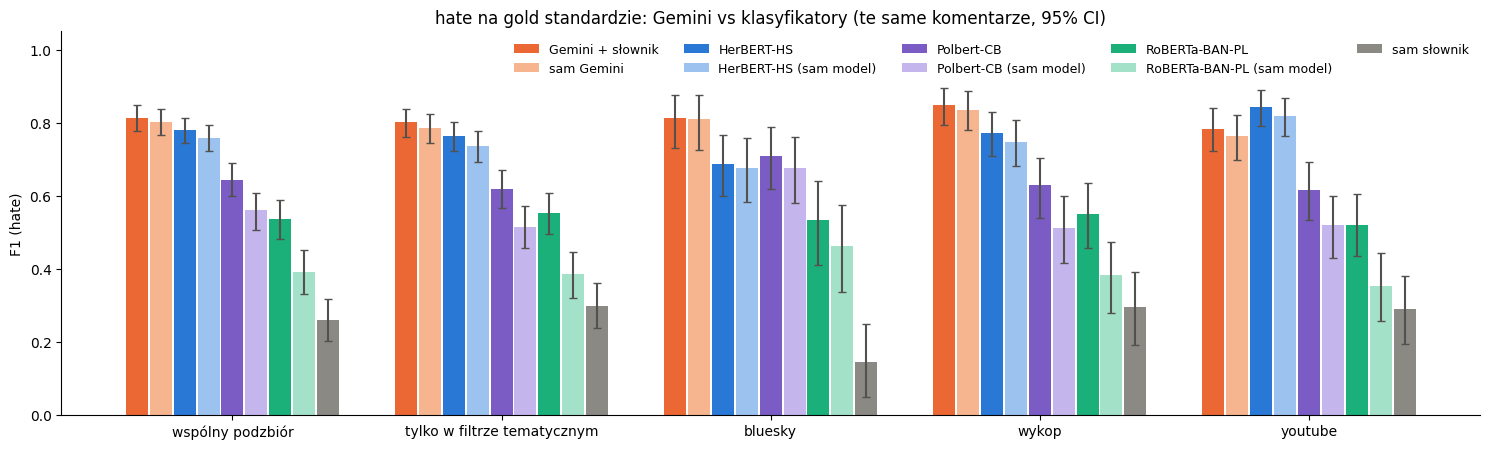

In [4]:
# F1 z 95% CI – wspólny podzbiór i per platforma
scopes = list(res["zakres"].unique())
names = list(METHODS)
colors = ["#eb6834", "#f6b48f", "#2a78d6", "#9cc3f0", "#7a5cc4", "#c4b5ec", "#1baf7a", "#a3e2c9", "#8a8984"]
fig, ax = plt.subplots(figsize=(15, 4.6))
w = 0.8 / len(names)
for i, name in enumerate(names):
    e = res[res["metoda"] == name].set_index("zakres").reindex(scopes)
    x = np.arange(len(scopes)) + (i - (len(names) - 1) / 2) * w
    lo = (e["f1"] - e["f1_ci95"].map(lambda v: v[0])).clip(lower=0)
    hi = (e["f1_ci95"].map(lambda v: v[1]) - e["f1"]).clip(lower=0)
    ax.bar(x, e["f1"], w * 0.92, color=colors[i % len(colors)], label=name, yerr=[lo, hi], capsize=3, ecolor="#52514e")
ax.set_xticks(range(len(scopes)), scopes)
ax.set_ylim(0, 1.05); ax.set_ylabel("F1 (hate)")
ax.set_title("hate na gold standardzie: Gemini vs klasyfikatory (te same komentarze, 95% CI)")
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, ncol=5, fontsize=9)
plt.tight_layout()
fig.savefig(OUT / "hate_gemini_vs_models.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Czy różnice są istotne? (Gemini vs każda metoda, te same komentarze)

In [5]:
def compare(data, scope):
    out = []
    a = data[METHODS[REFERENCE]].values
    for name, col in METHODS.items():
        if name == REFERENCE:
            continue
        b = data[col].values
        y = data["gold"].values
        ci, p_boot = boot_diff(y, a, b)
        n01, n10, p_mc = mcnemar(y, a, b)
        out.append({"zakres": scope, "porównanie": f"{REFERENCE} vs {name}", "n": len(y),
                    "F1 ref": round(scores(y, a)["f1"], 3), "F1 metody": round(scores(y, b)["f1"], 3),
                    "ΔF1 (ref − metoda)": round(scores(y, a)["f1"] - scores(y, b)["f1"], 3), "ΔF1 95% CI": ci,
                    "p (bootstrap ΔF1)": p_boot, "tylko ref trafił": n01, "tylko metoda trafiła": n10, "p (McNemar)": p_mc})
    return out


cmp_rows = compare(common, "wspólny podzbiór")
for plat, x in common.groupby("platform"):
    cmp_rows += compare(x, plat)
cmp = pd.DataFrame(cmp_rows)
for c in ["p (bootstrap ΔF1)", "p (McNemar)"]:
    cmp[c.replace("p (", "p Holm (")] = cmp.groupby("zakres")[c].transform(lambda s: multipletests(s, method="holm")[1])
show = cmp.copy()
for c in [c for c in show.columns if c.startswith("p ")]:
    show[c] = show[c].map(lambda v: f"{v:.3g}")
display(show.set_index(["zakres", "porównanie"]))

n  F1 ref  F1 metody  ΔF1 (ref − metoda)       ΔF1 95% CI p (bootstrap ΔF1)  tylko ref trafił  tylko metoda trafiła p (McNemar) p Holm (bootstrap ΔF1)  \
zakres           porównanie                                                                                                                                                                                                 
wspólny podzbiór Gemini + słownik vs sam Gemini                  600   0.814      0.801               0.012  [-0.002, 0.027]             0.098                10                     6       0.454                  0.196   
                 Gemini + słownik vs HerBERT-HS                  600   0.814      0.780               0.033  [-0.009, 0.075]             0.114                94                    60     0.00763                  0.196   
                 Gemini + słownik vs HerBERT-HS (sam model)      600   0.814      0.759               0.055    [0.01, 0.099]             0.015               108                    64    0.000986                  0.045   
                 Gemini + słownik vs Polbert-CB                  600   0.814      0.644               0.169   [0.123, 0.219]            0.0005               117                    35    1.58e-11                  0.004   
                 Gemini + słownik vs Polbert-CB (sam model)      600   0.814      0.560               0.254   [0.195, 0.313]            0.0005               151                    41    5.35e-16                  0.004   
                 Gemini + słownik vs RoBERTa-BAN-PL              600   0.814      0.535               0.279   [0.227, 0.334]            0.0005               131                    20    3.45e-21                  0.004   
                 Gemini + słownik vs RoBERTa-BAN-PL (sam model)  600   0.814      0.392               0.422   [0.358, 0.485]            0.0005               175                    27     9.6e-28                  0.004   
                 Gemini + słownik vs sam słownik                 600   0.814      0.260               0.554   [0.496, 0.614]            0.0005               190                    15    9.06e-40                  0.004   
bluesky          Gemini + słownik vs sam Gemini                  200   0.812      0.809               0.003  [-0.017, 0.025]             0.991                 1                     1           1                  0.991   
                 Gemini + słownik vs HerBERT-HS                  200   0.812      0.688               0.124   [0.036, 0.217]             0.002                35                    12     0.00109                   0.01   
                 Gemini + słownik vs HerBERT-HS (sam model)      200   0.812      0.675               0.136   [0.047, 0.232]             0.003                37                    13    0.000936                  0.012   
                 Gemini + słownik vs Polbert-CB                  200   0.812      0.708               0.103   [0.013, 0.196]             0.027                28                    12      0.0166                  0.054   
                 Gemini + słownik vs Polbert-CB (sam model)      200   0.812      0.676               0.135   [0.037, 0.237]             0.008                32                    13     0.00661                  0.024   
                 Gemini + słownik vs RoBERTa-BAN-PL              200   0.812      0.534               0.277   [0.159, 0.406]            0.0005                36                     8    2.54e-05                  0.004   
                 Gemini + słownik vs RoBERTa-BAN-PL (sam model)  200   0.812      0.463               0.349   [0.217, 0.491]            0.0005                42                    10    9.06e-06                  0.004   
                 Gemini + słownik vs sam słownik                 200   0.812      0.145               0.667    [0.55, 0.779]            0.0005                50                     5    2.14e-10                  0.004   
wykop            Gemini + słownik vs sam Gemini                  200   0.847      0.835  

## 3. Zgodność metod między sobą (κ Cohena, 600 komentarzy)

In [6]:
from itertools import combinations


def kappa(a, b):
    a, b = np.asarray(a, int), np.asarray(b, int)
    po = (a == b).mean(); pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return (po - pe) / (1 - pe) if pe < 1 else np.nan


cols_k = {"gold": common["gold"].values, **{n: common[c].values for n, c in METHODS.items()}}
k = pd.DataFrame(1.0, index=list(cols_k), columns=list(cols_k))
for a, b in combinations(cols_k, 2):
    k.loc[a, b] = k.loc[b, a] = round(kappa(cols_k[a], cols_k[b]), 3)
display(k)

,gold,Gemini + słownik,sam Gemini,HerBERT-HS,HerBERT-HS (sam model),Polbert-CB,Polbert-CB (sam model),RoBERTa-BAN-PL,RoBERTa-BAN-PL (sam model),sam słownik
gold,1.000,0.638,0.626,0.516,0.485,0.377,0.295,0.297,0.191,0.117
Gemini + słownik,0.638,1.000,0.945,0.493,0.429,0.474,0.323,0.462,0.263,0.239
sam Gemini,0.626,0.945,1.000,0.443,0.437,0.409,0.357,0.387,0.286,0.138
HerBERT-HS,0.516,0.493,0.443,1.000,0.940,0.461,0.340,0.316,0.166,0.160
HerBERT-HS (sam model),0.485,0.429,0.437,0.940,1.000,0.393,0.376,0.236,0.185,0.062
Polbert-CB,0.377,0.474,0.409,0.461,0.393,1.000,0.848,0.518,0.275,0.322
Polbert-CB (sam model),0.295,0.323,0.357,0.340,0.376,0.848,1.000,0.306,0.361,0.007
RoBERTa-BAN-PL,0.297,0.462,0.387,0.316,0.236,0.518,0.306,1.000,0.740,0.489
RoBERTa-BAN-PL (sam model),0.191,0.263,0.286,0.166,0.185,0.275,0.361,0.740,1.000,-0.046
sam słownik,0.117,0.239,0.138,0.160,0.062,0.322,0.007,0.489,-0.046,1.000


## 4. Wniosek (generowany automatycznie) i zapis

In [7]:
main = res[res["zakres"] == "wspólny podzbiór"].sort_values(["f1", "mcc"], ascending=False)
best = main.iloc[0]
lines = [f"Na wspólnym podzbiorze (n = {int(best['n'])}) najwyższe F1 dla hate ma {best['metoda']}: "
         f"{best['f1']:.3f} {best['f1_ci95']} (MCC {best['mcc']:.3f})."]
for _, r in cmp[cmp["zakres"] == "wspólny podzbiór"].iterrows():
    sig = "istotna" if r["p Holm (bootstrap ΔF1)"] < ALPHA else "nieistotna"
    lines.append(f"- {r['porównanie']}: ΔF1 = {r['ΔF1 (ref − metoda)']:+.3f} {r['ΔF1 95% CI']}, różnica {sig} "
                 f"(p Holm = {r['p Holm (bootstrap ΔF1)']:.3g}; McNemar p Holm = {r['p Holm (McNemar)']:.3g})")
for plat in ["wykop", "bluesky", "youtube"]:
    x = res[res["zakres"] == plat].sort_values("f1", ascending=False)
    if len(x):
        lines.append(f"- {plat} (n = {int(x.iloc[0]['n'])}): najlepsze F1 – {x.iloc[0]['metoda']} {x.iloc[0]['f1']:.3f}; "
                     f"Gemini + słownik {x[x['metoda'] == REFERENCE]['f1'].iloc[0]:.3f}, HerBERT {x[x['metoda'] == 'HerBERT-HS']['f1'].iloc[0]:.3f}")
print("\n".join(lines))

res.to_csv(OUT / "hate_gemini_vs_models.csv", index=False, encoding="utf-8-sig")
cmp.to_csv(OUT / "hate_gemini_vs_models_tests.csv", index=False, encoding="utf-8-sig")
(OUT / "hate_gemini_vs_models.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\nzapisano: hate_gemini_vs_models.csv, hate_gemini_vs_models_tests.csv, hate_gemini_vs_models.md, hate_gemini_vs_models.png")

Na wspólnym podzbiorze (n = 600) najwyższe F1 dla hate ma Gemini + słownik: 0.814 [0.778, 0.848] (MCC 0.653).
- Gemini + słownik vs sam Gemini: ΔF1 = +0.012 [-0.002, 0.027], różnica nieistotna (p Holm = 0.196; McNemar p Holm = 0.454)
- Gemini + słownik vs HerBERT-HS: ΔF1 = +0.033 [-0.009, 0.075], różnica nieistotna (p Holm = 0.196; McNemar p Holm = 0.0153)
- Gemini + słownik vs HerBERT-HS (sam model): ΔF1 = +0.055 [0.01, 0.099], różnica istotna (p Holm = 0.045; McNemar p Holm = 0.00296)
- Gemini + słownik vs Polbert-CB: ΔF1 = +0.169 [0.123, 0.219], różnica istotna (p Holm = 0.004; McNemar p Holm = 6.33e-11)
- Gemini + słownik vs Polbert-CB (sam model): ΔF1 = +0.254 [0.195, 0.313], różnica istotna (p Holm = 0.004; McNemar p Holm = 2.67e-15)
- Gemini + słownik vs RoBERTa-BAN-PL: ΔF1 = +0.279 [0.227, 0.334], różnica istotna (p Holm = 0.004; McNemar p Holm = 2.07e-20)
- Gemini + słownik vs RoBERTa-BAN-PL (sam model): ΔF1 = +0.422 [0.358, 0.485], różnica istotna (p Holm = 0.004; McNemar p H

## 5. Wykresy gold standardu (do raportu i prezentacji)

Wszystko na tych samych 600 komentarzach. Zapis: `reports/gold_gemini_eval/gold_*.png`.

In [8]:
# 5a. zgodność anotatorów gold (Claude vs Gemini, przed rozstrzygnięciem) i skład gold
agr_rows = []
for rnd in ["gold_v1", "gold_v2"]:
    f = ROOT / "data" / "annotation" / rnd / "results" / "agreement.json"
    if not f.exists():
        continue
    a = json.loads(f.read_text(encoding="utf-8"))
    for lab, key in [("hate", "hate"), ("hate_migrant", "hate_migrants")]:
        if key in a:
            r = {"runda": rnd, "etykieta": lab, "n": a[key]["all"]["n_items"], "α ogółem": a[key]["all"]["alpha"],
                 "95% CI": a[key]["all"]["alpha_ci95"], "pełna zgodność": a[key]["all"]["full_agreement"],
                 "α bez niepewnych": a[key].get("without_uncertain_items", {}).get("alpha")}
            for p, v in a[key].get("by_platform", {}).items():
                r[f"α {p}"] = v["alpha"]
            agr_rows.append(r)
if agr_rows:
    print("Zgodność dwóch anotatorów gold (α Krippendorffa; ≥ 0,667 = wystarczająca do wniosków wstępnych, ≥ 0,8 = dobra):")
    display(pd.DataFrame(agr_rows).set_index(["runda", "etykieta"]).round(3))
    print("Runda 2 nie ma zapisanej zgodności (results/agreement.json) – tylko rozstrzygnięcia (adjudication.xlsx).")
print("Skład gold (% hate):", ", ".join(f"{p} {100 * v:.0f}%" for p, v in d.groupby("platform")["gold"].mean().items()),
      f"| ogółem {100 * d['gold'].mean():.0f}% (n = {len(d)})")

Zgodność dwóch anotatorów gold (α Krippendorffa; ≥ 0,667 = wystarczająca do wniosków wstępnych, ≥ 0,8 = dobra):


n  α ogółem          95% CI  pełna zgodność  α bez niepewnych  α bluesky  α wykop  α youtube
runda   etykieta                                                                                                    
gold_v1 hate          600     0.666  [0.604, 0.726]           0.833             0.906      0.578    0.606      0.725
        hate_migrant  600     0.722  [0.659, 0.787]           0.897             0.983      0.485    0.693      0.742

Runda 2 nie ma zapisanej zgodności (results/agreement.json) – tylko rozstrzygnięcia (adjudication.xlsx).
Skład gold (% hate): bluesky 38%, wykop 60%, youtube 66% | ogółem 55% (n = 600)


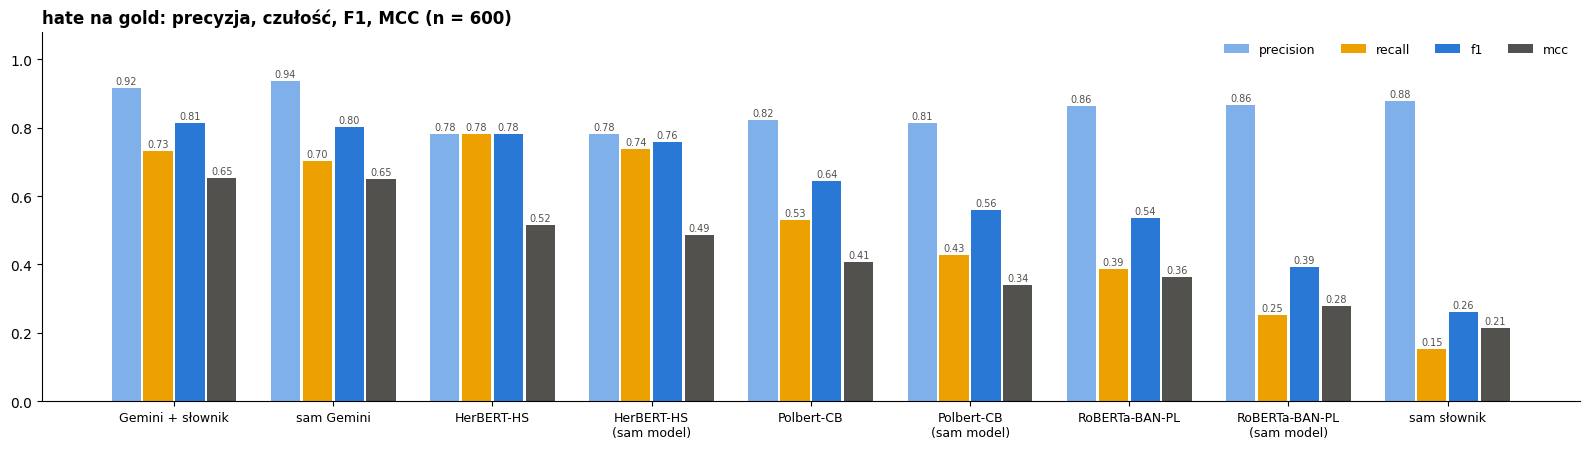

In [9]:
# 5b. precision / recall / F1 / MCC – wszystkie metody, oba warianty
order = list(METHODS)
mm = res[res["zakres"] == "wspólny podzbiór"].set_index("metoda").reindex(order)
fig, ax = plt.subplots(figsize=(16, 4.6))
w = 0.2
mcol = {"precision": "#7fb0ea", "recall": "#eda100", "f1": "#2a78d6", "mcc": "#52514e"}
for i, met in enumerate(["precision", "recall", "f1", "mcc"]):
    x = np.arange(len(order)) + (i - 1.5) * w
    ax.bar(x, mm[met], w * 0.92, color=mcol[met], label=met)
    for xi, v in zip(x, mm[met]):
        ax.text(xi, v + 0.012, f"{v:.2f}", ha="center", fontsize=7, color="#52514e")
ax.set_xticks(range(len(order)), [o.replace(" (sam model)", "\n(sam model)") for o in order], fontsize=9)
ax.set_ylim(0, 1.08); ax.legend(ncol=4, fontsize=9, frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"hate na gold: precyzja, czułość, F1, MCC (n = {int(mm['n'].iloc[0])})", loc="left", fontweight="bold")
plt.tight_layout(); fig.savefig(OUT / "gold_metryki.png", dpi=150, bbox_inches="tight"); plt.show()

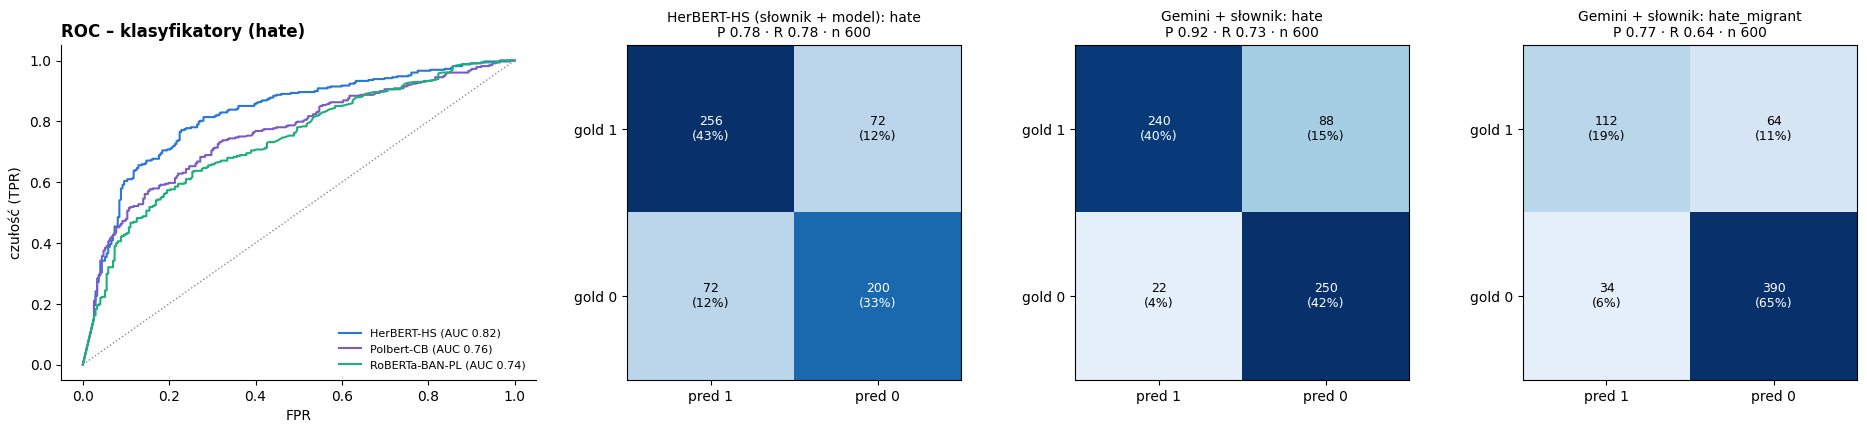

In [10]:
# 5c. ROC klasyfikatorów (score = max(prawdopodobieństwo, słownik)) + macierze pomyłek: HerBERT vs Gemini
def roc(y, s):
    o = np.argsort(-s, kind="mergesort"); y = np.asarray(y)[o]; s = np.asarray(s)[o]
    tps, fps = np.cumsum(y), np.cumsum(1 - y)
    keep = np.r_[np.diff(s) != 0, True]
    tpr, fpr = np.r_[0, tps[keep] / y.sum()], np.r_[0, fps[keep] / (1 - y).sum()]
    return fpr, tpr, float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))


def cm_plot(ax, y, p, title):
    y, p = np.asarray(y, int), np.asarray(p, int)
    m = np.array([[((y == 1) & (p == 1)).sum(), ((y == 1) & (p == 0)).sum()], [((y == 0) & (p == 1)).sum(), ((y == 0) & (p == 0)).sum()]])
    ax.imshow(m, cmap="Blues", vmin=0, vmax=m.max())
    for (i, j), v in np.ndenumerate(m):
        ax.text(j, i, f"{v}\n({100 * v / m.sum():.0f}%)", ha="center", va="center", fontsize=9, color="white" if v > 0.6 * m.max() else "black")
    ax.set_xticks([0, 1], ["pred 1", "pred 0"]); ax.set_yticks([0, 1], ["gold 1", "gold 0"])
    prec, rec = m[0, 0] / max(1, m[0, 0] + m[1, 0]), m[0, 0] / max(1, m[0, 0] + m[0, 1])
    ax.set_title(f"{title}\nP {prec:.2f} · R {rec:.2f} · n {m.sum()}", fontsize=10)


fig, axes = plt.subplots(1, 4, figsize=(19, 4.3), gridspec_kw={"width_ratios": [1.25, 1, 1, 1]})
ax = axes[0]
for m, col, name in [("herbert", "#2a78d6", "HerBERT-HS"), ("polbert", "#7a5cc4", "Polbert-CB"), ("roberta_banpl", "#1baf7a", "RoBERTa-BAN-PL")]:
    if f"prob_{m}" in d.columns:
        sc = np.maximum(d[f"prob_{m}"].astype(float).fillna(0).values, d["hate_auto"].astype(int).values)
        fpr, tpr, auc = roc(d["gold"].values, sc)
        ax.plot(fpr, tpr, color=col, label=f"{name} (AUC {auc:.2f})")
ax.plot([0, 1], [0, 1], ls=":", color="#8a8984", lw=1)
ax.set_xlabel("FPR"); ax.set_ylabel("czułość (TPR)"); ax.legend(fontsize=8, loc="lower right", frameon=False)
ax.set_title("ROC – klasyfikatory (hate)", loc="left", fontweight="bold"); ax.spines[["top", "right"]].set_visible(False)
cm_plot(axes[1], d["gold"], d["pred_herbert"], "HerBERT-HS (słownik + model): hate")
cm_plot(axes[2], d["gold"], d["llm_hate"], "Gemini + słownik: hate")
cm_plot(axes[3], d["gold_hate_migrant"], d["llm_hate_migrant"], "Gemini + słownik: hate_migrant")
plt.tight_layout(); fig.savefig(OUT / "gold_roc_macierze.png", dpi=150, bbox_inches="tight"); plt.show()

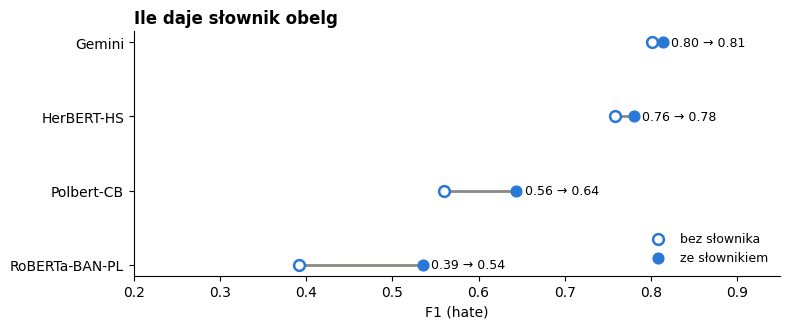

In [11]:
# 5d. ile daje słownik: wariant bez słownika vs ze słownikiem (F1 hate)
pairs = [("Gemini", "sam Gemini", "Gemini + słownik"), ("HerBERT-HS", "HerBERT-HS (sam model)", "HerBERT-HS"),
         ("Polbert-CB", "Polbert-CB (sam model)", "Polbert-CB"), ("RoBERTa-BAN-PL", "RoBERTa-BAN-PL (sam model)", "RoBERTa-BAN-PL")]
fig, ax = plt.subplots(figsize=(8, 3.4))
for yi, (lab, a, b) in enumerate(pairs):
    fa, fb = mm.loc[a, "f1"], mm.loc[b, "f1"]
    ax.plot([fa, fb], [yi, yi], color="#8a8984", lw=2)
    ax.scatter(fa, yi, s=60, facecolor="white", edgecolor="#2a78d6", lw=1.8, zorder=3, label="bez słownika" if yi == 0 else None)
    ax.scatter(fb, yi, s=60, color="#2a78d6", zorder=3, label="ze słownikiem" if yi == 0 else None)
    ax.text(max(fa, fb) + 0.01, yi, f"{fa:.2f} → {fb:.2f}", va="center", fontsize=9)
ax.set_yticks(range(len(pairs)), [p[0] for p in pairs]); ax.invert_yaxis(); ax.set_xlim(0.2, 0.95)
ax.set_xlabel("F1 (hate)"); ax.legend(frameon=False, fontsize=9, loc="lower right"); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Ile daje słownik obelg", loc="left", fontweight="bold")
plt.tight_layout(); fig.savefig(OUT / "gold_slownik.png", dpi=150, bbox_inches="tight"); plt.show()